# Week 12 – Support Vector Machine (SVM)
### Lab Exercises — Complete Solutions


---
## Question 1
**Task:** Use the Iris dataset with a linear-kernel SVM. Plot the scatter plot of the first two features and the decision boundary.


/usr/lib/python3.14/site-packages/sklearn/inspection/_plot/decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


TypeError: When passing handles and labels, they must both be passed positionally or both as keywords.

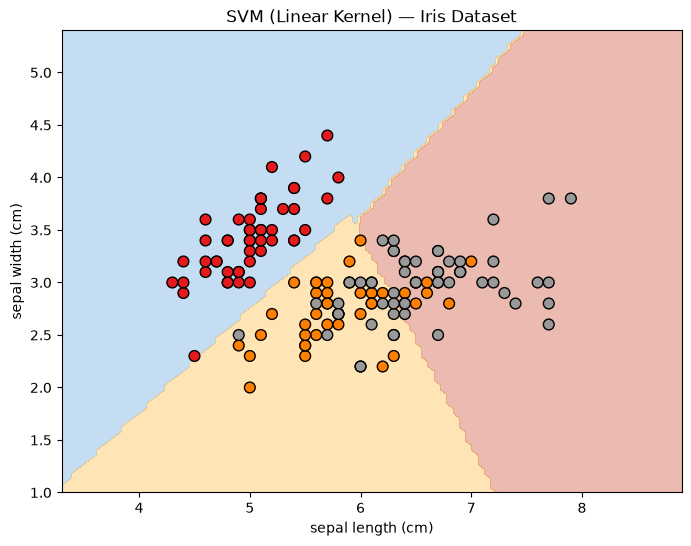

In [2]:
# ── Imports ────────────────────────────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

# ── Load dataset ────────────────────────────────────────────────────────────
iris = load_iris()
X = iris.data[:, :2]          # first two features: sepal length & sepal width
y = iris.target

# ── Train linear-kernel SVM ─────────────────────────────────────────────────
svm_linear = SVC(kernel="linear", C=1.0)
svm_linear.fit(X, y)

# ── Plot ────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

DecisionBoundaryDisplay.from_estimator(
    svm_linear, X,
    response_method="predict",
    cmap=plt.cm.Set1,
    alpha=0.3,
    ax=ax,
    xlabel=iris.feature_names[0],
    ylabel=iris.feature_names[1],
)

scatter = ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Set1,
                     edgecolors="k", s=60)
ax.set_title("SVM (Linear Kernel) — Iris Dataset")
legend1 = ax.legend(*scatter.legend_elements(), title="Classes",
                     labels=iris.target_names)
ax.add_artist(legend1)
plt.tight_layout()
plt.show()
print("Training accuracy:", svm_linear.score(X, y))


---
## Question 2
**Task:** Construct an SVM classifier on a small custom dataset.  
- **Positive (+1):** (4,1), (4,−1), (6,0)  
- **Negative (−1):** (1,0), (0,1), (0,−1)  

Plot the scatter and the separating hyperplane using scikit-learn.


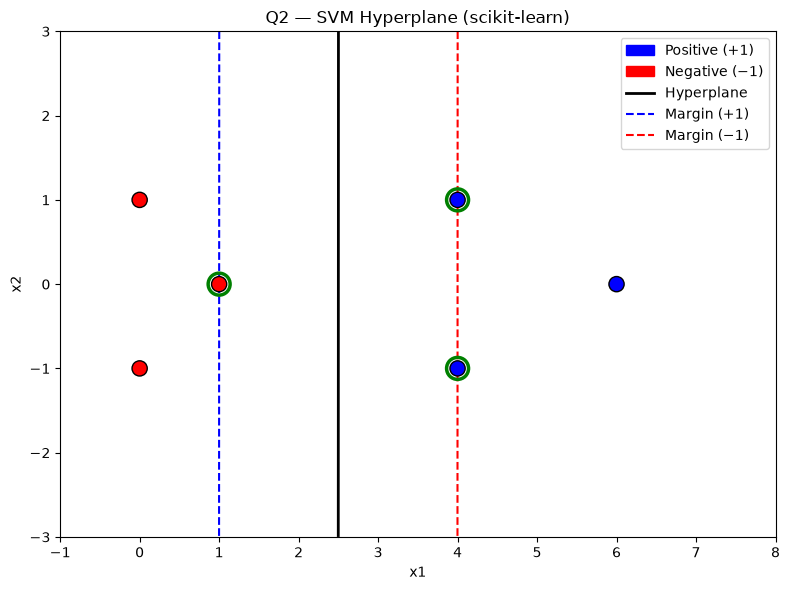

Hyperplane: 0.6667·x1 + -0.0003·x2 + -1.6669 = 0
Margin width: 2.9996
Support vectors:
[[ 1.  0.]
 [ 4.  1.]
 [ 4. -1.]]


In [3]:
# ── Data ────────────────────────────────────────────────────────────────────
X_q2 = np.array([[4,  1],
                  [4, -1],
                  [6,  0],
                  [1,  0],
                  [0,  1],
                  [0, -1]], dtype=float)

y_q2 = np.array([1, 1, 1, -1, -1, -1])

# ── Train SVM ───────────────────────────────────────────────────────────────
svm_q2 = SVC(kernel="linear", C=1e6)   # large C → hard-margin
svm_q2.fit(X_q2, y_q2)

# ── Decision boundary via sklearn ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))

xx = np.linspace(-1, 8, 400)
yy = np.linspace(-3, 3, 400)
XX, YY = np.meshgrid(xx, yy)
Z = svm_q2.decision_function(np.c_[XX.ravel(), YY.ravel()]).reshape(XX.shape)

# decision boundary and margins
ax.contour(XX, YY, Z, levels=[-1, 0, 1],
           linestyles=["--", "-", "--"],
           colors=["blue", "black", "red"],
           linewidths=[1.5, 2, 1.5])

# scatter
colors = ["red" if label == -1 else "blue" for label in y_q2]
ax.scatter(X_q2[:, 0], X_q2[:, 1], c=colors, s=120, edgecolors="k", zorder=5)

# mark support vectors
ax.scatter(svm_q2.support_vectors_[:, 0],
           svm_q2.support_vectors_[:, 1],
           s=250, facecolors="none", edgecolors="green",
           linewidths=2.5, label="Support Vectors", zorder=6)

ax.set_xlim(-1, 8)
ax.set_ylim(-3, 3)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Q2 — SVM Hyperplane (scikit-learn)")
ax.legend()

# annotate class regions
from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(color="blue",  label="Positive (+1)"),
    Patch(color="red",   label="Negative (−1)"),
    plt.Line2D([0],[0], color="black", lw=2, label="Hyperplane"),
    plt.Line2D([0],[0], color="blue",  lw=1.5, ls="--", label="Margin (+1)"),
    plt.Line2D([0],[0], color="red",   lw=1.5, ls="--", label="Margin (−1)"),
])
plt.tight_layout()
plt.show()

# Print hyperplane equation: w·x + b = 0
w = svm_q2.coef_[0]
b = svm_q2.intercept_[0]
print(f"Hyperplane: {w[0]:.4f}·x1 + {w[1]:.4f}·x2 + {b:.4f} = 0")
print(f"Margin width: {2 / np.linalg.norm(w):.4f}")
print(f"Support vectors:\n{svm_q2.support_vectors_}")


---
## Question 3
**Task:** Solve Question 2 **manually** (without scikit-learn) by solving the SVM dual problem using `scipy.optimize`.

### Manual Working (for Observation Book)

Given points:  
| Point | x1 | x2 | Label (y) |
|-------|----|----|-----------|
| p1    | 4  | 1  | +1        |
| p2    | 4  | −1 | +1        |
| p3    | 6  | 0  | +1        |
| p4    | 1  | 0  | −1        |
| p5    | 0  | 1  | −1        |
| p6    | 0  | −1 | −1        |

**Dual objective** (maximise):  
$$L(\alpha) = \sum_i \alpha_i - \frac{1}{2}\sum_i\sum_j \alpha_i\alpha_j y_i y_j (x_i \cdot x_j)$$

Subject to: $\alpha_i \geq 0$ and $\sum_i \alpha_i y_i = 0$.


Lagrange multipliers (alpha): [0.1111 0.1111 0.     0.2222 0.     0.    ]

Hyperplane (manual): 0.6667·x1 + -0.0000·x2 + -1.6667 = 0
Margin width (manual): 3.0000
Support vectors:
[[ 4.  1.]
 [ 4. -1.]
 [ 1.  0.]]


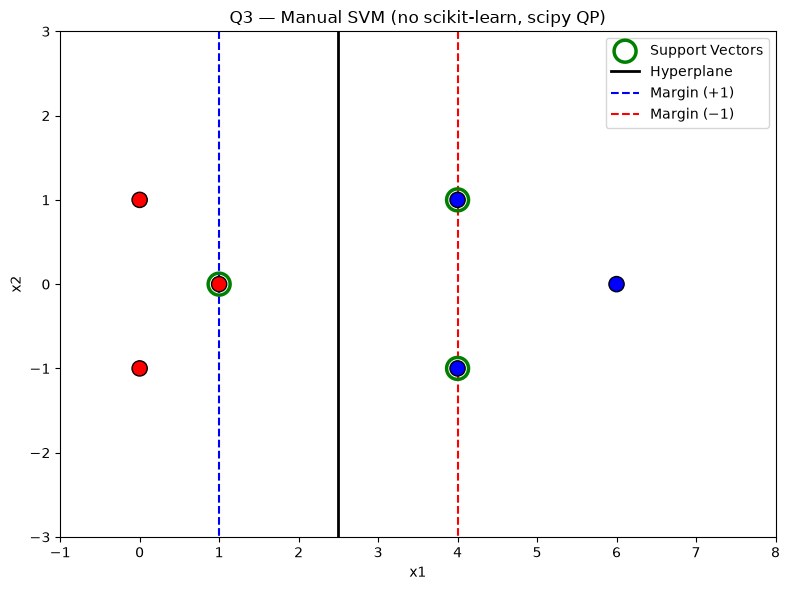

In [4]:
from scipy.optimize import minimize

# ── Data ────────────────────────────────────────────────────────────────────
X_q3 = np.array([[4,  1],
                  [4, -1],
                  [6,  0],
                  [1,  0],
                  [0,  1],
                  [0, -1]], dtype=float)
y_q3 = np.array([1, 1, 1, -1, -1, -1], dtype=float)
n = len(y_q3)

# Gram matrix  H[i,j] = y_i * y_j * (x_i · x_j)
H = np.outer(y_q3, y_q3) * (X_q3 @ X_q3.T)

# ── Dual objective (negate for minimisation) ────────────────────────────────
def dual_obj(alpha):
    return 0.5 * alpha @ H @ alpha - np.sum(alpha)

def dual_grad(alpha):
    return H @ alpha - np.ones(n)

# Constraints: sum(alpha_i * y_i) = 0
constraints = {"type": "eq",
               "fun":  lambda a: np.dot(a, y_q3),
               "jac":  lambda a: y_q3}

bounds = [(0, 1e6)] * n                # alpha_i >= 0

alpha0 = np.zeros(n)
result = minimize(dual_obj, alpha0,
                  jac=dual_grad,
                  method="SLSQP",
                  bounds=bounds,
                  constraints=constraints,
                  options={"ftol": 1e-12, "maxiter": 500})

alpha = result.x
print("Lagrange multipliers (alpha):", np.round(alpha, 4))

# ── Recover w and b ──────────────────────────────────────────────────────────
sv_mask = alpha > 1e-4
w_manual = np.sum((alpha[sv_mask] * y_q3[sv_mask])[:, None] * X_q3[sv_mask], axis=0)
b_manual = np.mean(y_q3[sv_mask] - X_q3[sv_mask] @ w_manual)

print(f"\nHyperplane (manual): {w_manual[0]:.4f}·x1 + {w_manual[1]:.4f}·x2 + {b_manual:.4f} = 0")
print(f"Margin width (manual): {2 / np.linalg.norm(w_manual):.4f}")
print(f"Support vectors:\n{X_q3[sv_mask]}")

# ── Plot ────────────────────────────────────────────────────────────────────
xx_q3 = np.linspace(-1, 8, 400)
# decision boundary: w[0]*x1 + w[1]*x2 + b = 0  → x2 = -(w[0]*x1+b)/w[1]
def boundary(x1, offset=0):
    return -(w_manual[0]*x1 + b_manual + offset) / w_manual[1]

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["red" if label == -1 else "blue" for label in y_q3]
ax.scatter(X_q3[:, 0], X_q3[:, 1], c=colors, s=120, edgecolors="k", zorder=5)
ax.scatter(X_q3[sv_mask, 0], X_q3[sv_mask, 1],
           s=250, facecolors="none", edgecolors="green", linewidths=2.5,
           label="Support Vectors", zorder=6)
ax.plot(xx_q3, boundary(xx_q3,  0), "k-",  lw=2,   label="Hyperplane")
ax.plot(xx_q3, boundary(xx_q3,  1), "b--", lw=1.5, label="Margin (+1)")
ax.plot(xx_q3, boundary(xx_q3, -1), "r--", lw=1.5, label="Margin (−1)")
ax.set_xlim(-1, 8); ax.set_ylim(-3, 3)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Q3 — Manual SVM (no scikit-learn, scipy QP)")
ax.legend(); plt.tight_layout(); plt.show()


---
## Question 4
**Task:** Sketch the hyperplane $1 + 2X_1 + 3X_2 = 0$.  
Indicate regions where $1 + 3X_1 - X_2 > 0$, $< 0$, and $= 0$  
for $x_1, x_2 \in [-10, 10]$ with $\pm 1$ grid.  Find slope & intercept.

### Manual Solution
**Hyperplane** $1 + 2x_1 + 3x_2 = 0$  
→ $x_2 = -\frac{2}{3}x_1 - \frac{1}{3}$  
Slope $= -2/3 \approx -0.667$,  Intercept $= -1/3 \approx -0.333$

**Region boundary** $1 + 3x_1 - x_2 = 0$  
→ $x_2 = 3x_1 + 1$  
Slope $= 3$,  Intercept $= 1$


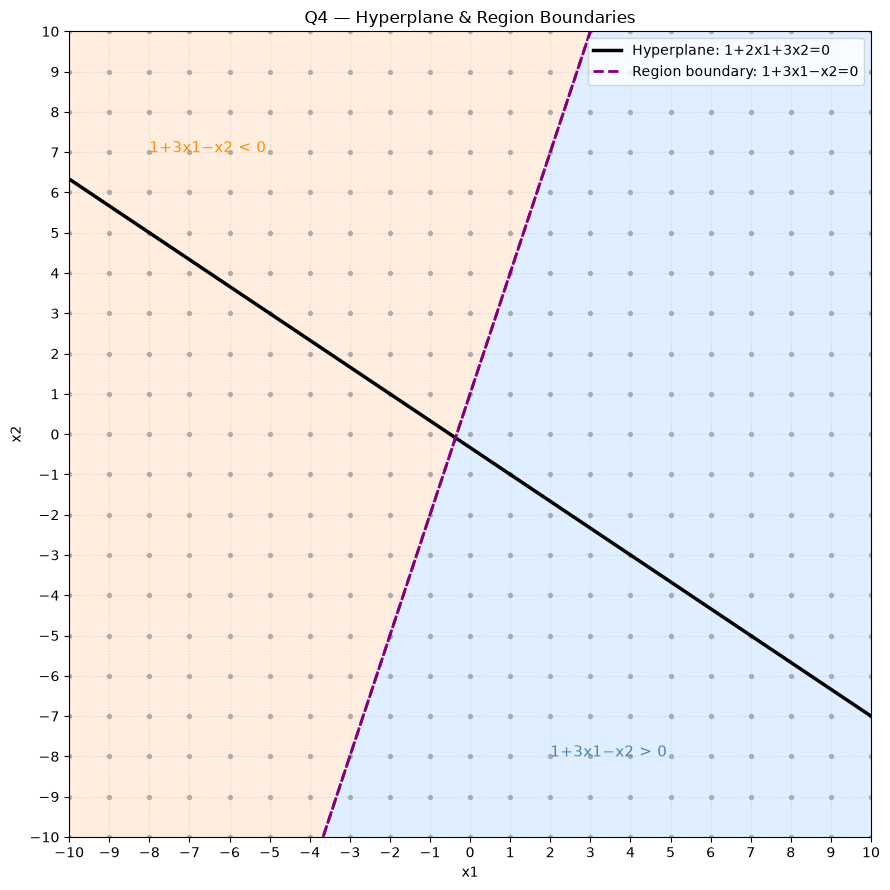

=== Hyperplane: 1 + 2x1 + 3x2 = 0 ===
  x2 = -(2/3)*x1 - (1/3)
  Slope     = -0.6667
  Intercept = -0.3333

=== Region boundary: 1 + 3x1 - x2 = 0 ===
  x2 = 3*x1 + 1
  Slope     = 3.0000
  Intercept = 1.0000


In [5]:
# ── Grid ────────────────────────────────────────────────────────────────────
x1_pts = np.arange(-10, 11, 1, dtype=float)
x2_pts = np.arange(-10, 11, 1, dtype=float)
X1, X2 = np.meshgrid(x1_pts, x2_pts)

expr = 1 + 3*X1 - X2      # for region colouring

fig, ax = plt.subplots(figsize=(9, 9))

# Colour regions of 1+3x1-x2
ax.contourf(X1, X2, expr, levels=[-1e6, 0, 1e6],
            colors=["#FFDDC1", "#C1E1FF"], alpha=0.5)
ax.contour(X1, X2, expr, levels=[0], colors="purple",
           linewidths=2, linestyles="--")

# Main hyperplane 1+2x1+3x2=0
x1_line = np.linspace(-10, 10, 400)
x2_hp   = -(1 + 2*x1_line) / 3
ax.plot(x1_line, x2_hp, "k-", lw=2.5, label="Hyperplane: 1+2x1+3x2=0")

# Region boundary 1+3x1-x2=0
x2_rb = 3*x1_line + 1
ax.plot(x1_line, x2_rb, "purple", lw=2, ls="--",
        label="Region boundary: 1+3x1−x2=0")

# Grid dots
ax.scatter(X1.ravel(), X2.ravel(), c="grey", s=8, alpha=0.5)

ax.set_xlim(-10, 10); ax.set_ylim(-10, 10)
ax.set_xticks(range(-10, 11)); ax.set_yticks(range(-10, 11))
ax.grid(True, ls=":", alpha=0.4)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Q4 — Hyperplane & Region Boundaries")
ax.legend(loc="upper right")

# Annotations
ax.text(-8,  7, "1+3x1−x2 < 0", fontsize=11, color="darkorange")
ax.text( 2, -8, "1+3x1−x2 > 0", fontsize=11, color="steelblue")
plt.tight_layout(); plt.show()

# ── Slope & Intercept ────────────────────────────────────────────────────────
print("=== Hyperplane: 1 + 2x1 + 3x2 = 0 ===")
print(f"  x2 = -(2/3)*x1 - (1/3)")
print(f"  Slope     = {-2/3:.4f}")
print(f"  Intercept = {-1/3:.4f}")
print()
print("=== Region boundary: 1 + 3x1 - x2 = 0 ===")
print(f"  x2 = 3*x1 + 1")
print(f"  Slope     = 3.0000")
print(f"  Intercept = 1.0000")


---
## Question 5
**Task:** Given two SVM classifiers:  
- **Classifier 1:** $5 + 2x_1 + 5x_2 = 0$  
- **Classifier 2:** $5 + 20x_1 + 50x_2 = 0$  

Find the best hyperplane, plot both on the same graph with region indicators, find slope & intercept.

### Manual Solution

Both represent the **same line** (Classifier 2 = 10 × Classifier 1), so geometrically identical.  

Margin $= \frac{2}{\|w\|}$  
- Classifier 1: $\|w_1\| = \sqrt{2^2+5^2} = \sqrt{29} \approx 5.385$, margin $\approx 0.371$  
- Classifier 2: $\|w_2\| = \sqrt{20^2+50^2} = \sqrt{2900} \approx 53.85$, margin $\approx 0.0371$  

**Classifier 1 is the better hyperplane** (larger normalised margin).


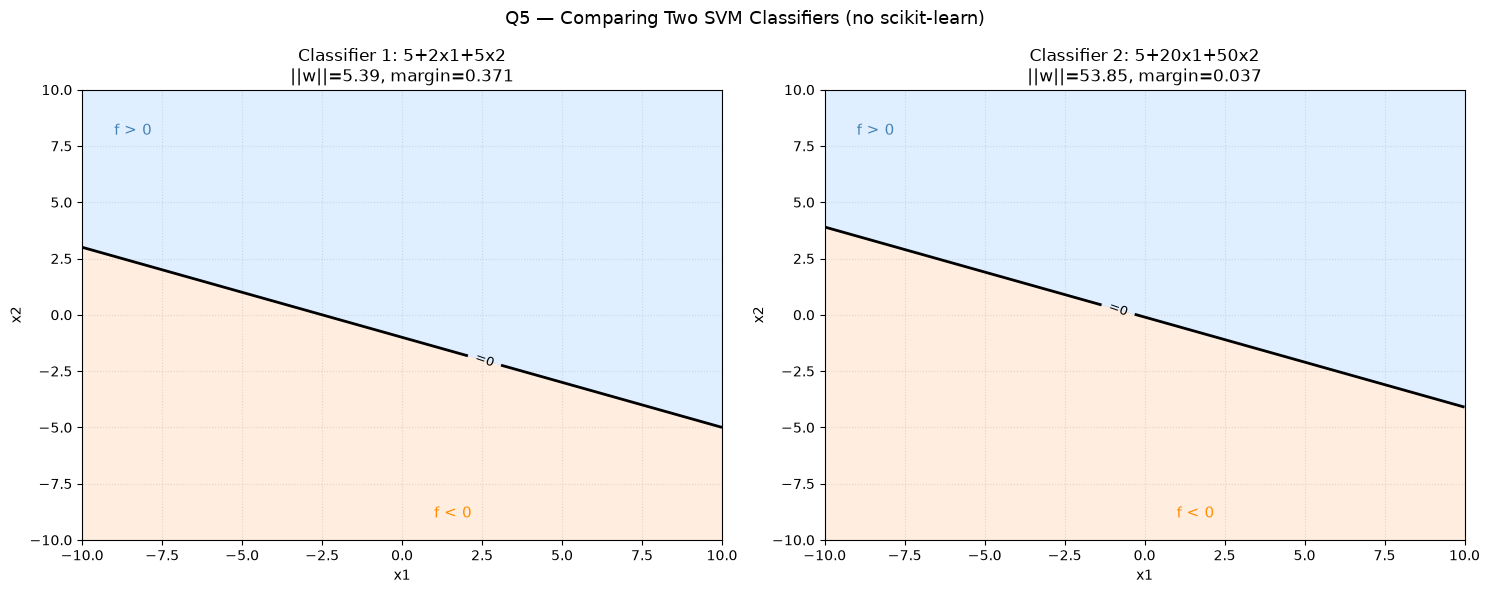

Classifier 1: 5+2x1+5x2=0
  x2 = (-0.4000)*x1 + (-1.0000)
  Slope=-0.4000, Intercept=-1.0000
  ||w||=5.3852, Margin=0.3714

Classifier 2: 5+20x1+50x2=0
  x2 = (-0.4000)*x1 + (-0.1000)
  Slope=-0.4000, Intercept=-0.1000
  ||w||=53.8516, Margin=0.0371

Best hyperplane → Classifier 1 (larger margin: 0.3714 > 0.0371)


In [6]:
# ── Grid ────────────────────────────────────────────────────────────────────
x1_g = np.linspace(-10, 10, 400)
x2_g = np.linspace(-10, 10, 400)
X1g, X2g = np.meshgrid(x1_g, x2_g)

f1 = 5 + 2*X1g  + 5*X2g
f2 = 5 + 20*X1g + 50*X2g

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, f, title, w_coef in zip(
        axes,
        [f1, f2],
        ["Classifier 1: 5+2x1+5x2", "Classifier 2: 5+20x1+50x2"],
        [[2, 5], [20, 50]]):

    ax.contourf(X1g, X2g, f,
                levels=[-1e6, 0, 1e6],
                colors=["#FFDDC1", "#C1E1FF"], alpha=0.5)
    cs = ax.contour(X1g, X2g, f,
                    levels=[0], colors="black", linewidths=2)
    ax.clabel(cs, fmt={0: "=0"}, fontsize=9)

    ax.text(-9,  8, f"f > 0", fontsize=11, color="steelblue")
    ax.text( 1, -9, f"f < 0", fontsize=11, color="darkorange")

    ax.set_xlim(-10, 10); ax.set_ylim(-10, 10)
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
    norm_w = np.linalg.norm(w_coef)
    ax.set_title(f"{title}\n||w||={norm_w:.2f}, margin={2/norm_w:.3f}")
    ax.grid(True, ls=":", alpha=0.4)

plt.suptitle("Q5 — Comparing Two SVM Classifiers (no scikit-learn)", fontsize=13)
plt.tight_layout(); plt.show()

# ── Slope & Intercept ────────────────────────────────────────────────────────
for label, b, w1, w2 in [("Classifier 1", 5, 2, 5), ("Classifier 2", 5, 20, 50)]:
    slope = -w1 / w2
    intercept = -b / w2
    norm = np.sqrt(w1**2 + w2**2)
    print(f"{label}: {b}+{w1}x1+{w2}x2=0")
    print(f"  x2 = ({slope:.4f})*x1 + ({intercept:.4f})")
    print(f"  Slope={slope:.4f}, Intercept={intercept:.4f}")
    print(f"  ||w||={norm:.4f}, Margin={2/norm:.4f}")
    print()

print("Best hyperplane → Classifier 1 (larger margin: 0.3714 > 0.0371)")
